# Check for columns that give the answer away

Runs on the cleaned data (`ml/data/phiusiil_cleaned.csv`, made by `03_clean_dataset.ipynb`), where **1 = phishing** and **0 = legitimate**. It looks for columns, and for URL shapes, that let a model guess the label for the wrong reason, so the first model learns real warning signs instead of shortcuts.

The checks live in `ml/leakage/` and are tested in `ml/tests/`. URLs are only read as text. None is opened or fetched.

| Section | Acceptance criterion |
|---|---|
| 1. URL shapes per class | 1 |
| 2. Single-feature accuracy | 2 |
| 3. `URLSimilarityIndex` on legitimate rows | 3 |
| 4. Does `FILENAME` give the label away? | 4 |
| 5. Excluded features | 5 |
| 6. URL-only columns left for the model | 6 |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


def find_ml_dir(start: Path) -> Path:
    """Walk up to the repo root (the folder holding AGENTS.md), so the notebook runs from any working directory inside the repo."""
    for folder in [start, *start.parents]:
        if (folder / "AGENTS.md").exists() and (folder / "ml").is_dir():
            return folder / "ml"
    raise FileNotFoundError("Could not find the ml/ folder. Open this notebook from inside the LinkGuard repo.")


ML_DIR = find_ml_dir(Path.cwd().resolve())
sys.path.insert(0, str(ML_DIR))

from cleaning.storage import CLEANED_CSV_NAME, load_cleaned  # noqa: E402
from leakage.columns import filename_leak, url_similarity_for_legitimate  # noqa: E402
from leakage.excluded import EXCLUDED_FEATURES, PAGE_CONTENT_COLUMNS, model_feature_columns  # noqa: E402
from leakage.homepage import bare_homepage_rule_accuracy, url_shape_by_class  # noqa: E402
from leakage.single_feature import LEAKY_ACCURACY_PERCENT, numeric_feature_columns, single_feature_accuracy  # noqa: E402

CLEANED_PATH = ML_DIR / "data" / CLEANED_CSV_NAME
REPORTS_DIR = ML_DIR / "reports"
if not CLEANED_PATH.exists():
    raise FileNotFoundError(f"Cleaned data not found at {CLEANED_PATH}. Run 03_clean_dataset.ipynb first.")

cleaned = load_cleaned(CLEANED_PATH)
print(f"Cleaned data: {len(cleaned):,} rows, {cleaned.shape[1]} columns")
print(f"Label counts: {cleaned['label'].value_counts().sort_index().to_dict()}  (0 = legitimate, 1 = phishing)")

Cleaned data: 235,370 rows, 56 columns
Label counts: {0: 134850, 1: 100520}  (0 = legitimate, 1 = phishing)


## 1. URL shapes per class

A **bare homepage** is `https://www.<domain>` with nothing after the domain except an optional trailing slash. Our research expects almost every legitimate URL to have this shape and most phishing URLs not to. This checks that on our own copy.

In [2]:
shapes = url_shape_by_class(cleaned)
rule_accuracy = bare_homepage_rule_accuracy(cleaned)

print(shapes.round(2).to_string())
print(f'\nRule "bare homepage means legitimate", on its own: {rule_accuracy:.2%} accurate')

                    Legitimate (%)  Phishing (%)
Bare homepage                100.0          1.03
Uses https                   100.0         48.63
Uses www.                    100.0         41.50
Has a path                     0.0         27.14
Has a query string             0.0          6.09

Rule "bare homepage means legitimate", on its own: 99.56% accurate


The research holds, and the template is stricter than expected: **every** legitimate URL in the dataset is a bare homepage, and almost no phishing URL is. So the legitimate class here means "a site's front page", not "a safe link". A real safe link such as `https://www.bank.example/login` has a shape the dataset only ever shows as phishing.

## 2. Single-feature accuracy

For each numeric column, a decision tree with one split (the best single threshold) is trained on that column alone and scored with 5-fold cross-validation. Any column over 95% is marked, because one threshold should not be enough to separate phishing from legitimate.

In [3]:
accuracy = single_feature_accuracy(cleaned, numeric_feature_columns(cleaned))
over_95 = accuracy[accuracy["Over 95%"]]

print(accuracy.round(2).to_string(index=False))
print(f"\n{len(over_95)} of {len(accuracy)} columns score over {LEAKY_ACCURACY_PERCENT}%: {over_95['Column'].tolist()}")

                    Column  Accuracy (%)  Over 95%
        URLSimilarityIndex         99.67      True
           NoOfExternalRef         96.13      True
                LineOfCode         95.53      True
               NoOfSelfRef         94.85     False
                 NoOfImage         94.26     False
                    NoOfJS         93.17     False
                   NoOfCSS         90.50     False
              HasSocialNet         88.01     False
          HasCopyrightInfo         86.57     False
            HasDescription         83.03     False
         LargestLineLength         82.40     False
NoOfOtherSpecialCharsInURL         79.53     False
     DomainTitleMatchScore         79.07     False
                   IsHTTPS         79.02     False
              IsResponsive         78.12     False
        URLTitleMatchScore         77.07     False
           HasSubmitButton         76.97     False
           DegitRatioInURL         76.02     False
           NoOfDegitsInURL     

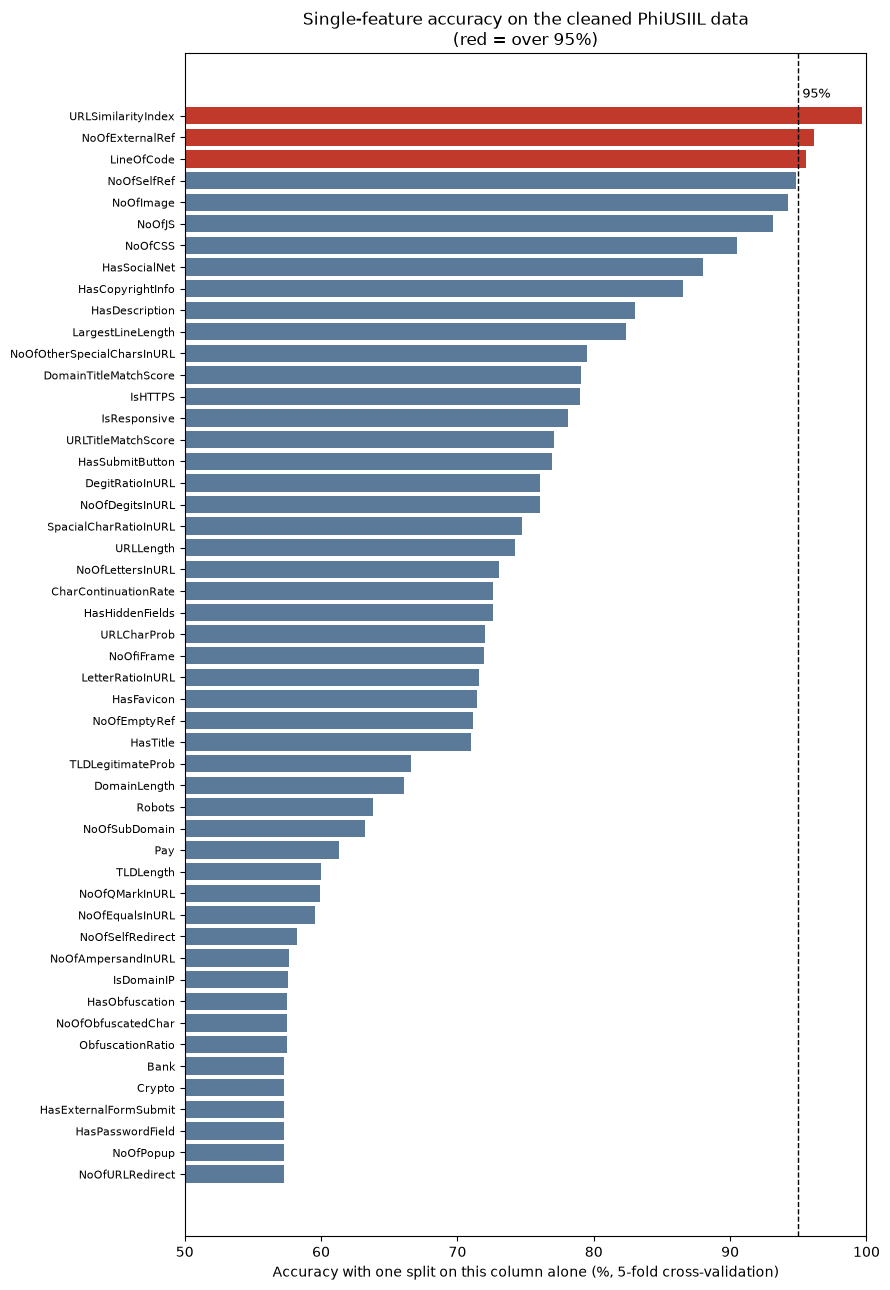

Saved ml/reports/single_feature_accuracy.png


In [4]:
CHART_PATH = REPORTS_DIR / "single_feature_accuracy.png"
LEAKY_COLOUR, OTHER_COLOUR = "#c0392b", "#5b7a99"

ordered = accuracy.iloc[::-1]  # highest at the top
colours = [LEAKY_COLOUR if leaky else OTHER_COLOUR for leaky in ordered["Over 95%"]]

fig, ax = plt.subplots(figsize=(9, 13))
ax.barh(ordered["Column"], ordered["Accuracy (%)"], color=colours)
ax.axvline(LEAKY_ACCURACY_PERCENT, color="black", linestyle="--", linewidth=1)
ax.text(LEAKY_ACCURACY_PERCENT, len(ordered) - 0.3, f" {LEAKY_ACCURACY_PERCENT}%", va="bottom", fontsize=9)
ax.set_xlim(50, 100)
ax.set_xlabel("Accuracy with one split on this column alone (%, 5-fold cross-validation)")
ax.set_title("Single-feature accuracy on the cleaned PhiUSIIL data\n(red = over 95%)")
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
fig.savefig(CHART_PATH, dpi=120)
plt.show()
print(f"Saved {CHART_PATH.relative_to(ML_DIR.parent)}")

## 3. `URLSimilarityIndex` on legitimate rows

The research found that every legitimate URL scores 100. The index measures how similar a URL is to the legitimate URLs themselves, so it would restate the label.

In [5]:
similarity = url_similarity_for_legitimate(cleaned)

print(f"Legitimate rows:            {similarity.rows:,}")
print(f"Min / max:                  {similarity.minimum:g} / {similarity.maximum:g}")
print(f"All legitimate rows at 100: {similarity.all_100}")
print(f"Phishing rows at 100:       {similarity.phishing_share_at_100:.2%}")
print("Finding confirmed." if similarity.all_100 else "Finding rejected: some legitimate rows are below 100.")

Legitimate rows:            134,850
Min / max:                  100 / 100
All legitimate rows at 100: True
Phishing rows at 100:       0.78%
Finding confirmed.


## 4. Does `FILENAME` give the label away?

`FILENAME` names the file each page was crawled into, such as `227338.txt`. Each name is reduced to its shape (letter prefix, number of digits, extension), and the shape alone is used to guess the label.

In [6]:
filenames = filename_leak(cleaned)

print(filenames.shapes.sort_values(["Legitimate", "Phishing"], ascending=False).to_string())
print(f"\nGuessing the label from the file name shape alone: {filenames.accuracy:.2%} accurate")
print(f"Shapes only ever seen on phishing rows: {len(filenames.phishing_only_shapes)}")

                     Legitimate  Phishing
Shape                                    
6 digits .txt            113020         0
5 digits .txt             20529         0
4 digits .txt              1153         0
3 digits .txt               140         0
2 digits .txt                 7         0
1 digit .txt                  1         0
7 digits .txt                 0     55021
mw + 5 digits .txt            0     18531
mw + 6 digits .txt            0     14015
oph + 5 digits .txt           0      8288
mw + 4 digits .txt            0      2098
other                         0      1666
op + 3 digits .txt            0       498
mw + 3 digits .txt            0       294
mw + 2 digits .txt            0        59
op + 2 digits .txt            0        44
op + 1 digit .txt             0         5
op + 4 digits .txt            0         1

Guessing the label from the file name shape alone: 100.00% accurate
Shapes only ever seen on phishing rows: 12


It does. Legitimate files are always a plain number of 6 digits or fewer (`227338.txt`). Phishing files from the other sources carry a prefix (`mw`, `oph`, `op`), 7 digits, or another name. The file name records which source a row came from, and each source holds one class, so it is excluded as an identifier.

## 5. Excluded features

The list lives in `ml/leakage/excluded.py` (`EXCLUDED_FEATURES`), so the first model reads its inputs from the same place this report does. The cell checks that every excluded name is a real column.

In [7]:
unknown = [column for column in EXCLUDED_FEATURES if column not in cleaned.columns]
if unknown:
    raise ValueError(f"Excluded columns not in the data: {unknown}")

excluded = pd.DataFrame(EXCLUDED_FEATURES.items(), columns=["Column", "Reason"])
print(f"{len(excluded)} columns excluded ({len(PAGE_CONTENT_COLUMNS)} of them page content).\n")
print(excluded.to_string(index=False))

36 columns excluded (28 of them page content).

               Column                                                                                                 Reason
   URLSimilarityIndex Restates the label: it measures similarity to the legitimate URLs, so every legitimate row scores 100.
    TLDLegitimateProb        Built from how often each TLD appears among legitimate URLs; its reference data is unpublished.
          URLCharProb           Built from character frequencies of the legitimate class; its reference data is unpublished.
             FILENAME                               Identifier: the crawl file name, whose shape alone gives the label away.
                  URL                          Identifier: raw text the URL feature extractor reads, never a feature itself.
               Domain        Identifier: the domain text, which would let the model memorise sites instead of warning signs.
                  TLD                                 Identifier: the TLD tex

## 6. URL-only columns left for the model

These are the columns the first model may use: every numeric column not excluded above, and not the label.

In [8]:
remaining = model_feature_columns(cleaned.columns.tolist())
remaining_accuracy = accuracy[accuracy["Column"].isin(remaining)]
remaining_over_95 = remaining_accuracy[remaining_accuracy["Over 95%"]]["Column"].tolist()

print(f"{len(remaining)} URL-only columns left.\n")
print(remaining_accuracy.round(2).to_string(index=False))
print(f"\nOver {LEAKY_ACCURACY_PERCENT}% on their own: {remaining_over_95 or 'none'}")

19 URL-only columns left.

                    Column  Accuracy (%)  Over 95%
NoOfOtherSpecialCharsInURL         79.53     False
                   IsHTTPS         79.02     False
           DegitRatioInURL         76.02     False
           NoOfDegitsInURL         76.02     False
     SpacialCharRatioInURL         74.75     False
                 URLLength         74.24     False
          NoOfLettersInURL         73.05     False
      CharContinuationRate         72.64     False
          LetterRatioInURL         71.61     False
              DomainLength         66.07     False
             NoOfSubDomain         63.20     False
                 TLDLength         59.98     False
            NoOfQMarkInURL         59.89     False
           NoOfEqualsInURL         59.58     False
        NoOfAmpersandInURL         57.67     False
                IsDomainIP         57.56     False
            HasObfuscation         57.50     False
        NoOfObfuscatedChar         57.50     False
    

None of the remaining URL-only columns scores over 95% on its own. **That does not make them safe.** The one-split check only tests one column at a time, and the legitimate-URL template is a combination of columns: `IsHTTPS = 1`, a `www.` subdomain, no path and no query string, which also keeps the special-character and digit counts low. A model that combines these columns can learn the template and separate the classes for the wrong reason, as the bare-homepage rule's score in section 1 shows. What to do about that is decided in the separate template-bias decision task, using these numbers.

## Save the report

Writes the numbers above to `ml/reports/leakage_report.md`, so the report always matches a real run.

In [9]:
def to_markdown_table(table: pd.DataFrame) -> str:
    def cell(value: object) -> str:
        if isinstance(value, float):
            return f"{value:.2f}"
        if isinstance(value, bool):
            return "YES" if value else ""
        return f"{value:,}" if isinstance(value, int) else str(value)

    header = "| " + " | ".join(table.columns) + " |"
    divider = "|" + "|".join("---" for _ in table.columns) + "|"
    body = ["| " + " | ".join(cell(value) for value in row) + " |" for row in table.itertuples(index=False)]
    return "\n".join([header, divider, *body])


shape_table = shapes.reset_index(names="URL shape")
filename_table = (
    filenames.shapes.sort_values(["Legitimate", "Phishing"], ascending=False).reset_index().astype({"Legitimate": int, "Phishing": int})
)
excluded_table = excluded.assign(Column=excluded["Column"].map(lambda name: f"`{name}`"))
accuracy_table = accuracy.assign(Column=accuracy["Column"].map(lambda name: f"`{name}`"))
over_95_names = ", ".join(f"`{name}`" for name in over_95["Column"])
remaining_names = ", ".join(f"`{name}`" for name in remaining_over_95) or "**none**"

report = f"""# PhiUSIIL leakage check

Generated by `ml/notebooks/04_leakage_check.ipynb` from the cleaned file `phiusiil_cleaned.csv` ({len(cleaned):,} rows; 1 = phishing, 0 = legitimate).
The checks are in `ml/leakage/`. URLs were only read as text; none was opened.

## 1. URL shapes per class

A bare homepage is `https://www.<domain>` with nothing after the domain except an optional trailing slash.

{to_markdown_table(shape_table)}

The rule "bare homepage means legitimate" on its own is **{rule_accuracy:.2%}** accurate. Every legitimate URL in the dataset is a site's front page, so a model can separate the classes by URL template alone.

## 2. Single-feature accuracy

Accuracy of a one-split decision tree on each numeric column alone, 5-fold cross-validated, sorted high to low. **{len(over_95)} of {len(accuracy)}** columns score over {LEAKY_ACCURACY_PERCENT}%: {over_95_names}. All of them are excluded below. Chart: `ml/reports/single_feature_accuracy.png`.

{to_markdown_table(accuracy_table.rename(columns={"Over 95%": f"Over {LEAKY_ACCURACY_PERCENT}%"}))}

## 3. `URLSimilarityIndex` on legitimate rows

- {similarity.rows:,} legitimate rows: min {similarity.minimum:g}, max {similarity.maximum:g}.
- **Finding {"confirmed" if similarity.all_100 else "rejected"}:** {"every" if similarity.all_100 else "not every"} legitimate row scores 100. Only {similarity.phishing_share_at_100:.2%} of phishing rows do.

## 4. `FILENAME`

**It gives the label away.** Guessing the label from the file name's shape alone is **{filenames.accuracy:.2%}** accurate. Legitimate files are a plain number of 6 digits or fewer; {len(filenames.phishing_only_shapes)} shapes (a prefix such as `mw`, `oph` or `op`, 7 digits, or another name) only appear on phishing rows. It records which source a row came from, so it is excluded as an identifier.

{to_markdown_table(filename_table)}

## 5. Excluded features

{len(excluded)} columns are left out of the first model ({len(PAGE_CONTENT_COLUMNS)} of them page content). The list is `EXCLUDED_FEATURES` in `ml/leakage/excluded.py`.

{to_markdown_table(excluded_table)}

## 6. URL-only columns left for the model

{len(remaining)} columns remain. Over {LEAKY_ACCURACY_PERCENT}% on their own: {remaining_names}.

**Passing this check does not make them safe.** It tests one column at a time, but the legitimate-URL template is a combination of columns (`IsHTTPS = 1`, a `www.` subdomain, no path and no query string, which also keeps the character counts low). A model that combines them can learn the template and separate the classes for the wrong reason. The fix is chosen in the separate template-bias decision task.
"""

REPORT_PATH = REPORTS_DIR / "leakage_report.md"
REPORT_PATH.write_text(report)
print(f"Saved {REPORT_PATH.relative_to(ML_DIR.parent)}")

Saved ml/reports/leakage_report.md
